## Mean Normalization

Mean Normalization is a feature scaling technique that transforms data by subtracting the mean of a feature from each value and dividing the result by the difference between its maximum and minimum values.

**Formula:**

$$
X' = \frac{X - \mu}{X_{\max} - X_{\min}}
$$

Where:
- $X$ = Original value
- $\mu$ = Mean of the feature
- $X_{\max}$ = Maximum value of the feature
- $X_{\min}$ = Minimum value of the feature

**Key observations:**
- The mean of the transformed feature is approximately 0.
- Values are centered around 0.


In [25]:
#IMPORTING BASIC LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [9]:
#Loading our dataset
data=pd.read_csv(r'D:\programming\datasets\wine_data.csv')
data.head()

,class_label,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,OD280/OD315_of_diluted_wines,proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [10]:
#we need only first three columns so:-
df=pd.read_csv(r'D:\programming\datasets\wine_data.csv',usecols=[0,1,2])
df.columns=['class_label' , 'alcohol' , 'malic_acid']
df.head()

,class_label,alcohol,malic_acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59


In [11]:
df.sample(7) #we get 3 class labels - 1,2,3

,class_label,alcohol,malic_acid
70,2,12.29,1.61
16,1,14.30,1.92
1,1,13.20,1.78
76,2,13.03,0.90
72,2,13.49,1.66
99,2,12.29,3.17
46,1,14.38,3.59


In [12]:
#Dividing our categorical and numerical data
df_categorical=df['class_label']
df_numerical=df.drop(columns=['class_label'])

In [13]:
df_numerical.sample(5)

,alcohol,malic_acid
66,13.11,1.01
159,13.48,1.67
0,14.23,1.71
24,13.50,1.81
164,13.78,2.76


In [14]:
df_categorical.sample(5)

150    3
24     1
3      1
38     1
2      1
Name: class_label, dtype: int64

## TRAIN_TEST_SPLIT ##

In [15]:
from sklearn.model_selection import train_test_split

X_train , X_test , y_train , y_test = train_test_split(df_numerical , df_categorical , test_size=0.3 , random_state=42)


In [16]:
np.round(X_train.mean(),1)

alcohol       13.0
malic_acid     2.4
dtype: float64

## MEAN NORMALIZATION ##

In [19]:
X_train_mean_norm = (X_train - X_train.mean()) / (X_train.max() - X_train.min())
X_test_mean_norm = (X_test - X_test.mean()) / (X_test.max() - X_test.min())

In [20]:
X_train_mean_norm

,alcohol,malic_acid
138,0.138604,0.241755
104,-0.119291,-0.137064
78,-0.166660,-0.287777
36,0.083340,-0.155394
93,-0.177186,0.086969
...,...,...
71,0.235972,-0.181870
106,-0.187712,-0.137064
14,0.372814,-0.108551
92,-0.071923,-0.177797


In [ ]:
np.round(X_train_mean_norm.mean(),1) #Mean becomes 0

alcohol      -0.0
malic_acid    0.0
dtype: float64

## GRAPHICAL REPRESENTATION ##

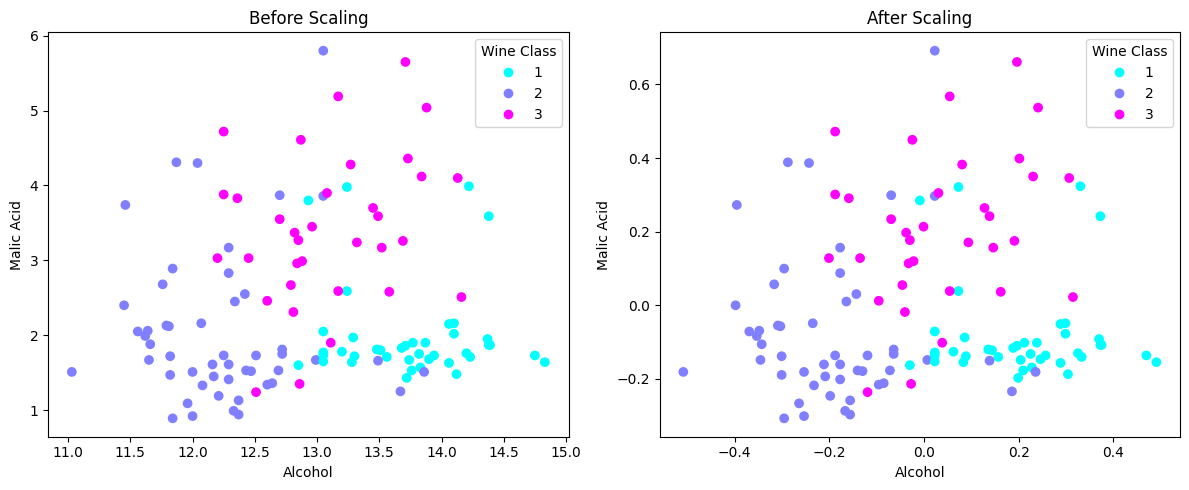

In [23]:
#Scatter plot 
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# Before scaling
scatter1 = ax1.scatter(
    X_train['alcohol'],
    X_train['malic_acid'],
    c=y_train,
    cmap='cool'
)
ax1.set_title('Before Scaling')
ax1.set_xlabel('Alcohol')
ax1.set_ylabel('Malic Acid')
ax1.legend(*scatter1.legend_elements(), title='Wine Class')

# After scaling
scatter2 = ax2.scatter(
    X_train_mean_norm['alcohol'],
    X_train_mean_norm['malic_acid'],
    c=y_train,
    cmap='cool'
)
ax2.set_title('After Scaling')
ax2.set_xlabel('Alcohol')
ax2.set_ylabel('Malic Acid')
ax2.legend(*scatter2.legend_elements(), title='Wine Class')

plt.tight_layout()
plt.show()

#only range changed to 0,1 rest graphical representation is same

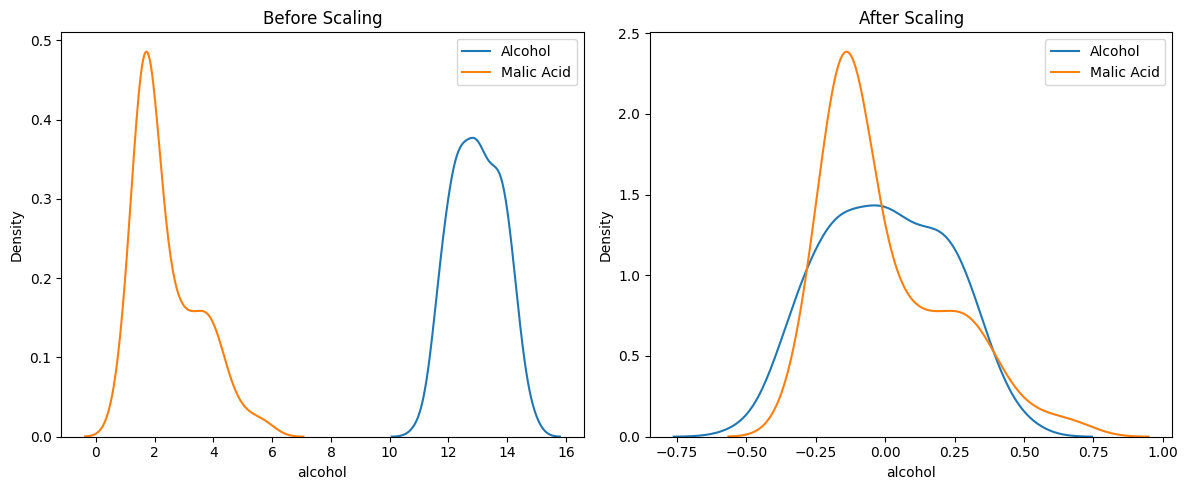

In [ ]:
#Kdeplots
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# Before scaling
sns.kdeplot(x=X_train['alcohol'], ax=ax1, label='Alcohol')
sns.kdeplot(x=X_train['malic_acid'], ax=ax1, label='Malic Acid')
ax1.set_title('Before Scaling')
ax1.legend()

# After scaling
sns.kdeplot(x=X_train_mean_norm['alcohol'], ax=ax2, label='Alcohol')
sns.kdeplot(x=X_train_mean_norm['malic_acid'], ax=ax2, label='Malic Acid')
ax2.set_title('After Scaling')
ax2.legend()

plt.tight_layout()
plt.show()

# After mean normalization, both features are centered around zero and their numerical ranges become more comparable. However, their minimum and maximum values are not necessarily the same.